# Forecast Using the Timestral Family


In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q timecopilot


TimeCopilot ships a single `Timestral` class for Mistral AI's [Timestral](https://huggingface.co/collections/mistralai/timestral) checkpoints. Pass the Hugging Face `repo_id` to select the size:

| Size | `repo_id` | Parameters (approx.) |
|------|-----------|----------------------|
| **Timestral-5M** | `mistralai/Timestral-5M` | 5M |
| **Timestral-28M** | `mistralai/Timestral-28M` | 28M |
| **Timestral-123M** | `mistralai/Timestral-123M` | 123M |
| **Timestral-209M** | `mistralai/Timestral-209M` | 209M |

Timestral forecasts zero-shot with 21 quantile levels (0.01–0.99), up to 32,768 steps of context, and native known-future covariates (see the [exogenous variables example](exogenous-variables.ipynb)). This notebook compares all four sizes on event pageview data using the univariate API.

By default, `Timestral` sets `symmetric_averaging=True` and `clip_nonnegative=True`, matching Mistral's published benchmark settings.

*Requirements:*

    - Python 3.10+
    - timecopilot-timestral>=0.1.0 (installed with timecopilot)

**License:** inference code is Apache-2.0 via `timecopilot-timestral`. Checkpoint weights use Mistral's Modified MIT license (companies above USD 20M monthly revenue need a commercial license from Mistral).

In this example we compare all four Timestral sizes on event pageview data.

## Import libraries



In [2]:
import sys

import pandas as pd

from timecopilot import TimeCopilotForecaster

if sys.version_info < (3, 10):
    raise RuntimeError("Timestral requires Python >= 3.10")


/private/tmp/ff-timestral/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO:datasets:JAX version 0.7.1 available.


## Load the dataset

The DataFrame must include at least the following columns:
- unique_id: Unique identifier for each time series (string)
- ds: Date column (datetime format)
- y: Target variable for forecasting (float format)

The pandas frequency will be inferred from the ds column, if not provided.
If the seasonality is not provided, it will be inferred based on the frequency.
If the horizon is not set, it will default to 2 times the inferred seasonality.



In [3]:
df = pd.read_csv(
    "https://timecopilot.s3.amazonaws.com/public/data/events_pageviews.csv",
    parse_dates=["ds"],
)
df.head()


,unique_id,ds,y
0,Oktoberfest,2020-01-31,25376
1,Oktoberfest,2020-02-29,28470
2,Oktoberfest,2020-03-31,23816
3,Oktoberfest,2020-04-30,46186
4,Oktoberfest,2020-05-31,31213


## Plot the data



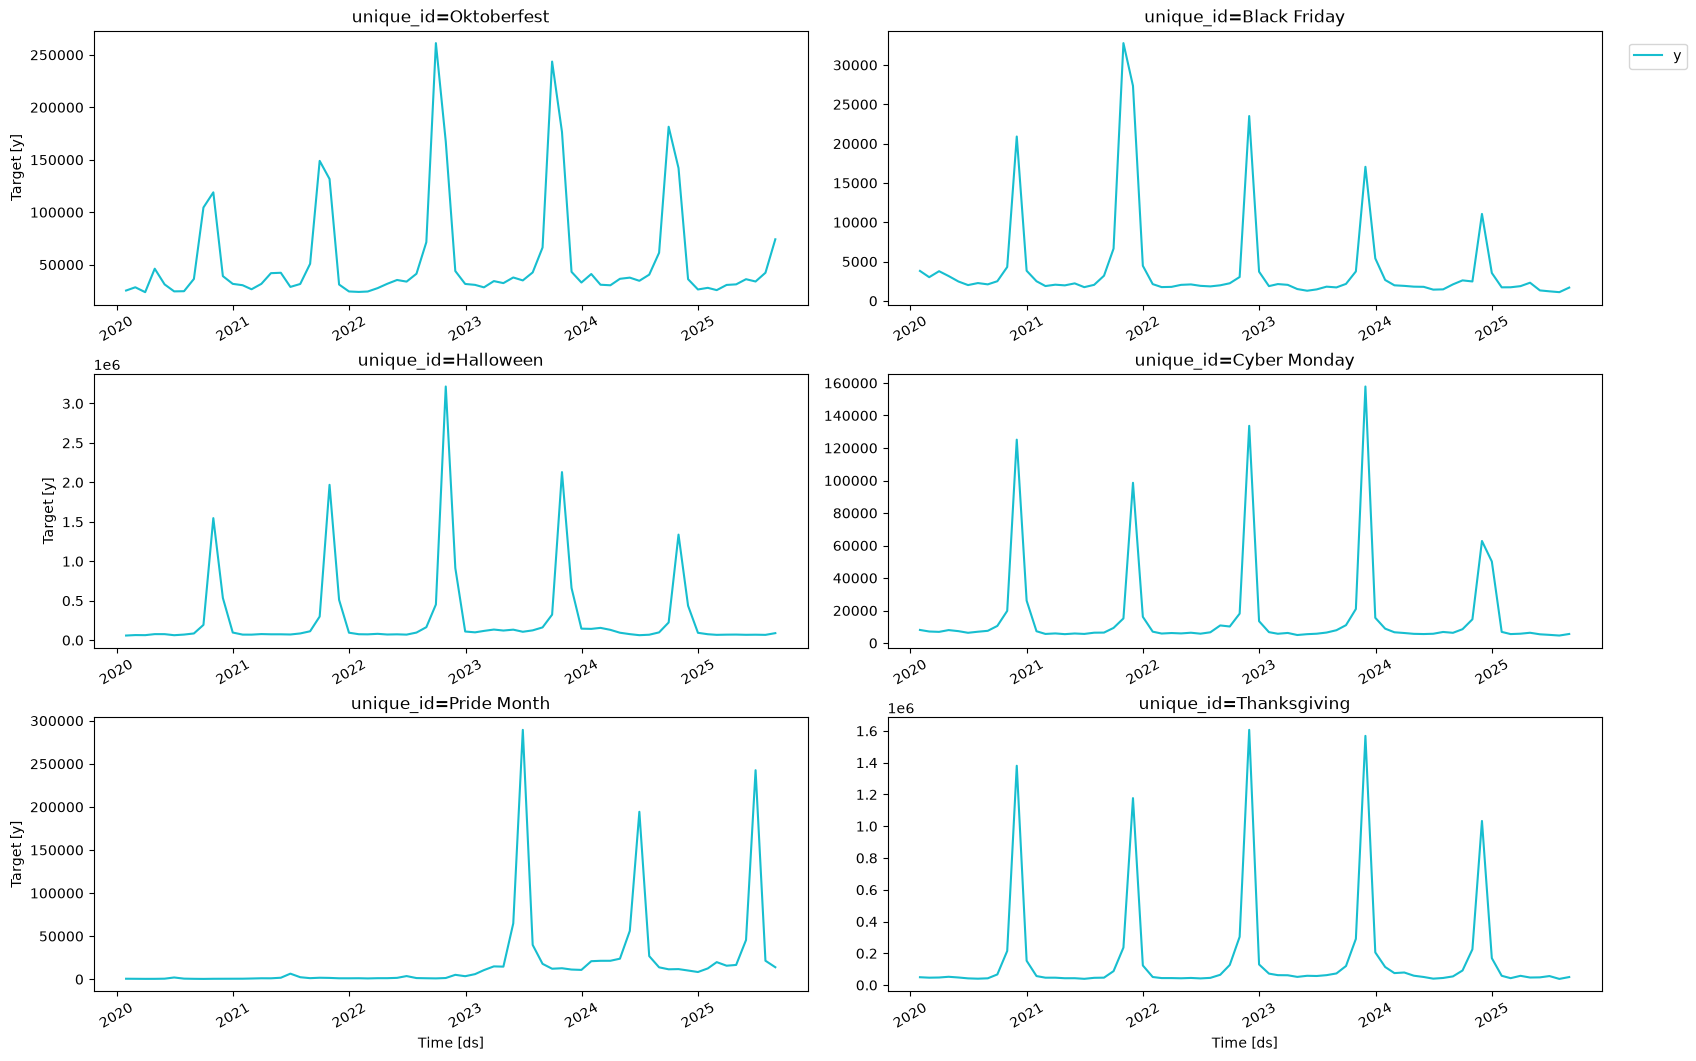

In [4]:
TimeCopilotForecaster.plot(df)


## Import the models



In [5]:
from timecopilot.models.foundation import Timestral


## Create a TimeCopilotForecaster

We compare all four Timestral sizes. Each model gets a distinct `alias` so its forecasts are easy to identify.


In [6]:
models = [
    Timestral(repo_id="mistralai/Timestral-5M", alias="Timestral-5M", context_length=512, batch_size=2),
    Timestral(repo_id="mistralai/Timestral-28M", alias="Timestral-28M", context_length=512, batch_size=2),
    Timestral(repo_id="mistralai/Timestral-123M", alias="Timestral-123M", context_length=512, batch_size=2),
    Timestral(repo_id="mistralai/Timestral-209M", alias="Timestral-209M", context_length=512, batch_size=2),
]

tcf = TimeCopilotForecaster(models=models)


## Generate forecast

You can optionally specify the following parameters:
- freq: The frequency of your data (e.g., 'D' for daily, 'M' for monthly)
- h: The forecast horizon, which is the number of periods to predict
- seasonality: The seasonal period of your data, which can be inferred if not provided



In [7]:
level = [20, 40, 50, 60, 80] 
cv_df = tcf.cross_validation(df=df, h=12, level=level)


0it [00:00, ?it/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1606.09it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:00<00:00, 68.27it/s]

...

 67%|██████▋   | 2/3 [00:00<00:00,  6.41it/s]

100%|██████████| 3/3 [00:00<00:00,  6.47it/s]

100%|██████████| 3/3 [00:00<00:00,  6.44it/s]


1it [00:27, 27.49s/it]

1it [00:27, 27.49s/it]

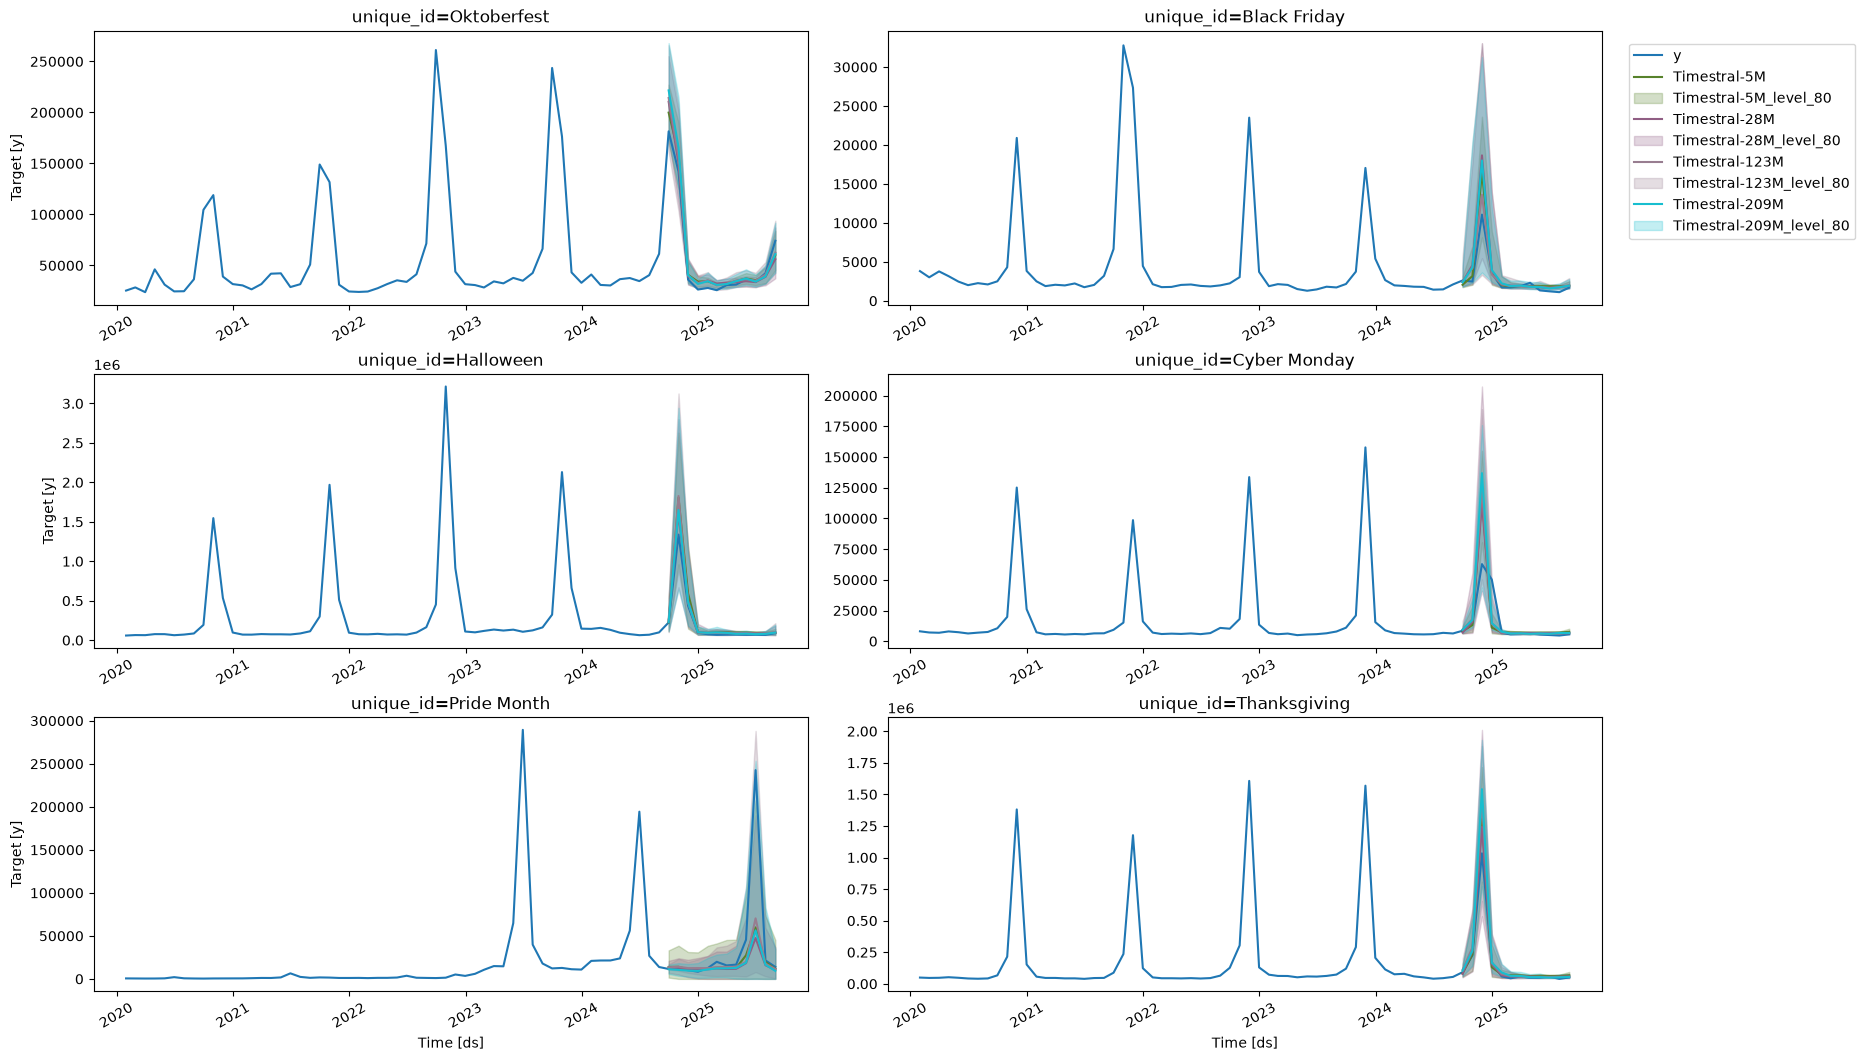

In [8]:
tcf.plot(df, cv_df.drop(columns=["cutoff", "y"]), level=[80])


In [9]:
cv_df.head()


,unique_id,ds,cutoff,y,Timestral-5M,Timestral-5M-lo-20,Timestral-5M-hi-20,Timestral-5M-lo-40,Timestral-5M-hi-40,Timestral-5M-lo-50,...,Timestral-209M-lo-20,Timestral-209M-hi-20,Timestral-209M-lo-40,Timestral-209M-hi-40,Timestral-209M-lo-50,Timestral-209M-hi-50,Timestral-209M-lo-60,Timestral-209M-hi-60,Timestral-209M-lo-80,Timestral-209M-hi-80
0,Black Friday,2024-09-30,2024-08-31,2607,2051.674805,1960.315308,2125.059082,1904.075073,2262.517578,1890.706421,...,2229.193848,2556.166504,2121.232422,2807.971191,2047.502075,2989.498779,1975.001953,3226.597656,1803.005371,4534.183594
1,Black Friday,2024-10-31,2024-08-31,2470,3172.327148,2717.263916,3521.658691,2475.853760,4686.390137,2435.821777,...,3523.760254,5252.361328,3046.702393,7386.128906,2826.235352,9242.813477,2659.160645,11848.419922,2326.291260,20434.636719
2,Black Friday,2024-11-30,2024-08-31,11058,16588.050781,15257.862305,17929.291016,14329.717773,19981.382812,13031.036133,...,15010.613281,21193.958984,10599.210938,23189.093750,8151.651367,24754.468750,6296.561523,26371.363281,3633.005371,31281.675781
3,Black Friday,2024-12-31,2024-08-31,3548,3632.194824,2849.701416,4025.409424,2662.328125,5128.262207,2481.042969,...,3539.111816,4348.863281,3239.265625,5050.150879,3077.065430,5675.650391,2904.433105,6682.150391,2416.286865,11981.496094
4,Black Friday,2025-01-31,2024-08-31,1724,1987.868286,1870.559326,2071.230469,1830.375977,2244.912598,1793.431152,...,2133.045166,2346.728027,2030.706055,2482.752441,1960.809082,2574.124023,1898.926025,2698.052979,1750.200073,3113.784668


## Evaluation



In [10]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mase, scaled_crps


In [11]:
eval_df = evaluate(
    cv_df.drop(columns=["cutoff"]),
    train_df=df.query("ds <= '2024-08-31'"),
    metrics=[partial(mase, seasonality=12), scaled_crps],
    level=level,
)
eval_df.groupby("metric").mean(numeric_only=True).T.sort_values(
    by="scaled_crps"
).round(3)


metric,mase,scaled_crps
Timestral-123M,1.210,0.268
Timestral-28M,1.077,0.270
Timestral-5M,1.173,0.287
Timestral-209M,1.337,0.291
